**Installing all the relavant libraries**

In [1]:
pip install pandas numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


# Case Studies for **EIE**


**Python Script: Sensor Data Imputation Framework**

This experiment creates a mock dataset representing an industrial boiler system (Temperature, Pressure, and Flow Rate) with missing sensor logs, detects the gaps, and applies three common engineering imputation methods:
1. Mean Imputation (Best for stable, non-fluctuating metrics)
2. Forward Fill / Time-Series Propagation (Best for continuous physical processes where the next second is highly dependent on the previous second)
3. K-Nearest Neighbors (KNN) Imputation (Best for complex multi-variable correlations)


In [2]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer

# 1. Create a simulated Instrument Log with missing data (NaN)
# Let's assume a telemetry packet drops occasionally
raw_sensor_data = {
    'Timestamp': pd.date_range(start="2026-10-22 09:00", periods=8, freq="min"),
    'Temperature_C': [150.2, 150.5, np.nan, 152.1, 153.0, np.nan, 151.8, 150.9],
    'Pressure_PSI':  [30.1, np.nan, 30.5, 31.0, np.nan, 30.8, 30.2, 30.0],
    'Flow_Rate_LPM': [5.1, 5.2, 5.1, np.nan, 5.5, 5.4, np.nan, 5.2]
}

df = pd.DataFrame(raw_sensor_data).set_index('Timestamp')
print("--- 1. Original Dataset with Missing Logs ---")
print(df)
print("\n" + "="*50 + "\n")

# =====================================================================
# STEP 2: FIND MISSING VALUES
# =====================================================================
print("--- 2. Missing Value Analysis ---")
# Count missing values per sensor channel
missing_count = df.isnull().sum()
# Calculate percentage of data loss
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_status = pd.DataFrame({
    'Missing Count': missing_count,
    'Data Loss (%)': missing_percentage
})
print(missing_status)
print("\n" + "="*50 + "\n")

# =====================================================================
# STEP 3: PERFORM DATA IMPUTATION
# =====================================================================
print("--- 3. Data Imputation Strategies ---")

# Strategy A: Mean Imputation (Fills gaps with the historical average)
df_mean = df.copy()
df_mean['Temperature_C'] = df_mean['Temperature_C'].fillna(df_mean['Temperature_C'].mean())
print("\nA. Mean Imputation (Applied to Temperature):")
print(df_mean[['Temperature_C']])

# Strategy B: Forward Fill (Propagates the last valid sensor reading forward)
# Highly effective for slow-changing thermodynamic properties like pressure
df_ffill = df.copy()
df_ffill['Pressure_PSI'] = df_ffill['Pressure_PSI'].ffill()
print("\nB. Forward Fill (Applied to Pressure):")
print(df_ffill[['Pressure_PSI']])

# Strategy C: Advanced KNN Imputation (Predicts missing values using multi-channel correlations)
# Useful when sensors influence or track each other (e.g., higher pressure correlates to higher flow)
knn_imputer = KNNImputer(n_neighbors=2)
# KNN Imputer operates on numerical arrays and strips column names, so we rebuild the DataFrame
imputed_array = knn_imputer.fit_transform(df)
df_knn = pd.DataFrame(imputed_array, columns=df.columns, index=df.index)

print("\nC. KNN Imputer (Applied to entire matrix - note Flow Rate results):")
print(df_knn[['Flow_Rate_LPM']])

# =====================================================================
# STEP 4: EXPORTING CLEAN DATA
# =====================================================================
# Combining preferred methods into one finalized production dataset
final_clean_df = df.copy()
final_clean_df['Temperature_C'] = final_clean_df['Temperature_C'].fillna(final_clean_df['Temperature_C'].mean())
final_clean_df['Pressure_PSI'] = final_clean_df['Pressure_PSI'].ffill()
final_clean_df['Flow_Rate_LPM'] = df_knn['Flow_Rate_LPM'] # Using KNN for Flow Rate

print("\n" + "="*50 + "\n")
print("--- 4. Final Imputed & Calibrated Telemetry Dataset ---")
print(final_clean_df.round(2))


--- 1. Original Dataset with Missing Logs ---
                     Temperature_C  Pressure_PSI  Flow_Rate_LPM
Timestamp                                                      
2026-10-22 09:00:00          150.2          30.1            5.1
2026-10-22 09:01:00          150.5           NaN            5.2
2026-10-22 09:02:00            NaN          30.5            5.1
2026-10-22 09:03:00          152.1          31.0            NaN
2026-10-22 09:04:00          153.0           NaN            5.5
2026-10-22 09:05:00            NaN          30.8            5.4
2026-10-22 09:06:00          151.8          30.2            NaN
2026-10-22 09:07:00          150.9          30.0            5.2


--- 2. Missing Value Analysis ---
               Missing Count  Data Loss (%)
Temperature_C              2           25.0
Pressure_PSI               2           25.0
Flow_Rate_LPM              2           25.0


--- 3. Data Imputation Strategies ---

A. Mean Imputation (Applied to Temperature):
                


**Python Script: Instrumentation Sensor Outlier Detection Framework**

This script generates a simulated dataset representing an industrial factory line monitoring Chamber Pressure (PSI). It manually injects outliers (simulating sensor spikes/line noise) and applies both statistical frameworks to isolate them.

*   Aim: To evaluate raw instrumentation sensor streams, implement mathematical outlier detection models (Z-Score and IQR), and accurately identify process anomalies or sensor hardware faults.
*   Discussion: In EIE applications, an outlier is not just a mathematical anomaly; it represents an actual physical scenario such as a transducer failing, line noise, or a process deviation. The Z-Score method functions optimally when data has a clean bell curve. However, for real-world industrial machinery data that shifts dynamically, the IQR method is highly robust because it relies on distribution quartiles and cannot be skewed by massive sudden spikes during the calculation.



--- 1. Sensor Telemetry Array Initialized (100 Sample Points) ---
       Pressure_PSI
count        100.00
mean          49.71
std            9.17
min           -5.00
25%           48.69
50%           49.79
75%           51.00
max           95.20


--- METHOD 1: Z-Score Outlier Detection ---
Identified 4 anomalies using Z-Threshold > 3.0:
    Pressure_PSI  Z_Score
15          95.2     4.99
42          12.1     4.12
67          88.7     4.28
88          -5.0     6.00


--- METHOD 2: IQR (Tukey's Fences) Outlier Detection ---
Process Bounds Established -> Lower: 45.23 PSI | Upper: 54.46 PSI
Identified 5 anomalies using IQR boundaries:
    Pressure_PSI
15         95.20
42         12.10
67         88.70
74         44.76
88         -5.00




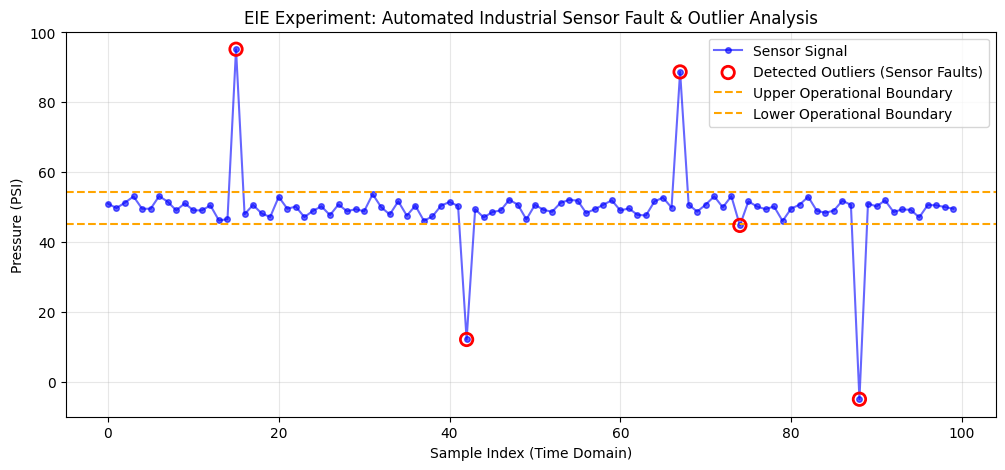

In [3]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# 1. Simulate a Industrial Pressure Sensor Dataset with Injected Faults
np.random.seed(42)
normal_pressure = np.random.normal(loc=50.0, scale=2.0, size=100) # Baseline process: 50 PSI average

# Manually inject 4 distinct hardware anomalies/sensor spikes (Outliers)
outliers_idx = [15, 42, 67, 88]
normal_pressure[15] = 95.2   # Huge voltage spike
normal_pressure[42] = 12.1   # Sensor grounding fault / drop
normal_pressure[67] = 88.7   # Transient pressure surge
normal_pressure[88] = -5.0   # Broken wire / negative reading anomaly

# Load into a structured DataFrame
df = pd.DataFrame({'Pressure_PSI': normal_pressure})
print("--- 1. Sensor Telemetry Array Initialized (100 Sample Points) ---")
print(df.describe().round(2))
print("\n" + "="*70 + "\n")


# =====================================================================
# METHOD 1: Z-SCORE METHOD (Parametric Approach)
# =====================================================================
print("--- METHOD 1: Z-Score Outlier Detection ---")
# Z-Score measures how many standard deviations a data point is from the mean.
# In instrumentation engineering, a threshold of |Z| > 3 is standard for anomalies.

threshold_z = 3.0
df['Z_Score'] = np.abs(stats.zscore(df['Pressure_PSI']))

# Filter data points exceeding threshold
z_outliers = df[df['Z_Score'] > threshold_z]

print(f"Identified {len(z_outliers)} anomalies using Z-Threshold > {threshold_z}:")
print(z_outliers[['Pressure_PSI', 'Z_Score']].round(2))
print("\n" + "="*70 + "\n")


# =====================================================================
# METHOD 2: INTERQUARTILE RANGE (IQR) METHOD (Non-Parametric Approach)
# =====================================================================
print("--- METHOD 2: IQR (Tukey's Fences) Outlier Detection ---")
# IQR isolates anomalies without assuming a perfect normal distribution.
# It identifies any point outside: [Q1 - 1.5*IQR] to [Q3 + 1.5*IQR]

Q1 = df['Pressure_PSI'].quantile(0.25)
Q3 = df['Pressure_PSI'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

iqr_outliers = df[(df['Pressure_PSI'] < lower_bound) | (df['Pressure_PSI'] > upper_bound)]

print(f"Process Bounds Established -> Lower: {lower_bound:.2f} PSI | Upper: {upper_bound:.2f} PSI")
print(f"Identified {len(iqr_outliers)} anomalies using IQR boundaries:")
print(iqr_outliers[['Pressure_PSI']].round(2))
print("\n" + "="*70 + "\n")


# =====================================================================
# VISUALIZATION: LAB DATA PLOT
# =====================================================================
plt.figure(figsize=(12, 5))

# Plot full sensor trace
plt.plot(df.index, df['Pressure_PSI'], label='Sensor Signal', color='blue', alpha=0.6, marker='o', markersize=4)

# Highlight identified anomalies (Using IQR results)
plt.scatter(iqr_outliers.index, iqr_outliers['Pressure_PSI'], color='red', s=80, zorder=5,
            label='Detected Outliers (Sensor Faults)', facecolors='none', edgecolors='red', linewidths=2)

# Draw upper/lower operational limits
plt.axhline(upper_bound, color='orange', linestyle='--', label='Upper Operational Boundary')
plt.axhline(lower_bound, color='orange', linestyle='--', label='Lower Operational Boundary')

plt.title('EIE Experiment: Automated Industrial Sensor Fault & Outlier Analysis')
plt.xlabel('Sample Index (Time Domain)')
plt.ylabel('Pressure (PSI)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()




* Aim: To evaluate raw data acquisition logs, differentiate between complete row mirroring and partial feature conflicts, and apply resolution methods to preserve temporal consistency.
*   Discussion: In EIE applications, resolving duplicates requires system-level context.

1. Exact duplicates (where every sensor value matches) are safe to drop using .drop_duplicates(keep='first') because they represent simple network buffering noise.
2.   Partial duplicates (where the Timestamp matches but sensor parameters like Boiler_Temp_C differ drastically) indicate a sensor calibration crash or clock skew. In high-stakes monitoring, taking the mathematical mean (.groupby().mean()) or prioritizing the freshest packet (keep='last') protects the downstream control algorithms from executing commands based on corrupted readings.





In [4]:
import pandas as pd
import numpy as np

# 1. GENERATE CASE STUDY DATASET (Simulated Boiler Telemetry Matrix)
scada_logs = {
    'Timestamp': [
        '2026-10-22 10:00:00',
        '2026-10-22 10:00:01',
        '2026-10-22 10:00:01',  # Complete duplicate (Row error)
        '2026-10-22 10:00:02',
        '2026-10-22 10:00:03',
        '2026-10-22 10:00:03',  # Duplicate timestamp, different values (Sensor sync error)
        '2026-10-22 10:00:04'
    ],
    'Boiler_Temp_C': [210.5, 210.8, 210.8, 211.2, 212.0, 295.4, 211.9],
    'Vibration_mms': [4.2,   4.5,   4.5,   4.6,   4.8,   9.1,   4.7]
}

df = pd.DataFrame(scada_logs)
print("--- 1. Raw Incoming SCADA Dataset (With Network Duplication) ---")
print(df)
print("\n" + "="*70 + "\n")


# =====================================================================
# STEP 2: IDENTIFY DUPLICATE SAMPLES
# =====================================================================
print("--- 2. Auditing Duplicates ---")

# A. Locate exact identical rows across the entire record
exact_duplicates = df[df.duplicated(keep=False)]
print(f"Identified {len(df[df.duplicated()])} exact row duplicates:")
print(exact_duplicates)

# B. Locate duplicate instances strictly tied to the hardware Time-Stamp
# (Useful when a sensor shouldn't log multiple entries at the exact same millisecond)
timestamp_duplicates = df[df.duplicated(subset=['Timestamp'], keep=False)]
print("\nIdentified conflicts locked to the same Temporal Metric (Timestamp):")
print(timestamp_duplicates)
print("\n" + "="*70 + "\n")


# =====================================================================
# STEP 3: METHODS TO HANDLE DUPLICATE DATA
# =====================================================================
print("--- 3. Strategic Resolution Methods ---")

# Method A: Standard Purge (Keep the FIRST log, delete trailing mirror records)
# Best when a network buffer just repeated a transmission sequence.
df_method_a = df.drop_duplicates(keep='first')
print("\nMethod A: Retaining the FIRST entry of exact duplicates:")
print(df_method_a)

# Method B: Keep Last (Retain the LAST log entry)
# Best if hardware updates parameters sequentially and the final packet is the most updated state.
df_method_b = df.drop_duplicates(subset=['Timestamp'], keep='last')
print("\nMethod B: Enforcing unique timestamps by retaining the LATEST entry:")
print(df_method_b)

# Method C: Comprehensive Hardware Purge (Delete ALL instances of duplicated telemetry)
# Best if duplicate signals signify corruption or unsafe sensor crosstalk.
df_method_c = df.drop_duplicates(keep=False)
print("\nMethod C: Total Purge (Dropping all corrupted overlapping data rows entirely):")
print(df_method_c)

# Method D: Conditional Statistical Aggregation (Grouping conflicting timestamps)
# If a hardware sync issue occurs, average the conflicting readings out to estimate real telemetry.
df_method_d = df.groupby('Timestamp', as_index=False).mean()
print("\nMethod D: Data Aggregation (Averaging conflicting entries per timestamp):")
print(df_method_d.round(2))


--- 1. Raw Incoming SCADA Dataset (With Network Duplication) ---
             Timestamp  Boiler_Temp_C  Vibration_mms
0  2026-10-22 10:00:00          210.5            4.2
1  2026-10-22 10:00:01          210.8            4.5
2  2026-10-22 10:00:01          210.8            4.5
3  2026-10-22 10:00:02          211.2            4.6
4  2026-10-22 10:00:03          212.0            4.8
5  2026-10-22 10:00:03          295.4            9.1
6  2026-10-22 10:00:04          211.9            4.7


--- 2. Auditing Duplicates ---
Identified 1 exact row duplicates:
             Timestamp  Boiler_Temp_C  Vibration_mms
1  2026-10-22 10:00:01          210.8            4.5
2  2026-10-22 10:00:01          210.8            4.5

Identified conflicts locked to the same Temporal Metric (Timestamp):
             Timestamp  Boiler_Temp_C  Vibration_mms
1  2026-10-22 10:00:01          210.8            4.5
2  2026-10-22 10:00:01          210.8            4.5
4  2026-10-22 10:00:03          212.0            4.8
5 

**Perform data normalization**

In instrumentation systems, different sensors monitor entirely different physical properties, meaning their outputs have vastly different units and scales. For example, a industrial SCADA system might simultaneously monitor:
* Boiler Temperature: 100°C to 300°CList item
* Gas Pressure: 1.0 to 5.0 Bar
* Control Valve Position (PWM): 0 to 255 (dimensionless)
If you feed these raw values directly into a predictive maintenance model or an automated fault detection algorithm, the temperature values will completely dominate the calculations purely due to their larger numerical scale. Data Normalization scales all sensor channels to a uniform range without distorting the underlying differences in the data patterns.
We will implement the two most critical normalization methods used in process automation:

1.   Min-Max Scaling (Normalization): Rescales data linearly into a strict [0, 1] range. Perfect for fixed-bound hardware arrays (like converting raw 8-bit or 10-bit ADC signals into a uniform percentage scale).
2.   Z-Score Standardization (Standardization): Centers the data so it has a mean of 0 and a standard deviation of 1. Excellent for predictive algorithms because it handles noisy sensor spikes and outliers robustly.



**Industrial Multi-Sensor Scaling Framework**
This script simulates a multi-sensor array monitoring a steam turbine system. We will parse the raw heterogeneous instrumentation logs and apply both normalization frameworks.

* Aim: To implement and evaluate Min-Max Scaling and Z-Score Standardization algorithms on multi-unit telemetry matrices to ensure uniform weight distribution across diverse operational parameters.
* Discussion: In industrial automation, raw sensor arrays present data in mismatched physical bounds (Celsius vs. Bar).
	1. Min-Max Scaling transforms the arrays into a localized absolute range of \([0, 1]\). This mirrors standard hardware operations, such as scaling an arbitrary voltage loop (4 mA to 20 mA) to a standard 0% to 100% control scale. However, if a boiler experiences a massive unexpected temperature surge, Min-Max bounds compress the normal operating resolution heavily.
	2. Z-Score Standardization eliminates this boundary vulnerability by scaling data based on variance. Because it establishes a mean baseline of 0, positive outputs signify an above-average physical load, while negative numbers highlight sub-optimal system operational states, providing a robust dataset for calibration models.


In [5]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. GENERATE CASE STUDY DATASET (Simulated Turbine Telemetry)
# Note the drastically different ranges and dimensions of each sensor
instrumentation_data = {
    'Log_ID':[101,102,103,104,105],
    'Temperature_C': [150.0, 280.0, 190.0, 220.0, 250.0],  # High values
    'Pressure_Bar':   [1.2,   4.5,   2.1,   3.0,   3.8],    # Low values
    'Valve_Opening_Pct': [10.0,  95.0,  40.0,  60.0,  75.0]  # Percentage scale
}

df = pd.DataFrame(instrumentation_data).set_index('Log_ID')
print("--- 1. Raw Heterogeneous Instrumentation Dataset ---")
print(df)
print("\n" + "="*75 + "\n")


# =====================================================================
# METHOD 1: MIN-MAX SCALING (Strict 0 to 1 Bounds)
# =====================================================================
print("--- METHOD 1: Min-Max Scaling [0, 1] ---")
# Formula: X_scaled = (X - X_min) / (X_max - X_min)

min_max_scaler = MinMaxScaler()
# Fit and transform the numerical sensor matrix
df_min_max = pd.DataFrame(
    min_max_scaler.fit_transform(df),
    columns=df.columns,
    index=df.index
)

print("Scaled Sensor Matrix (All metrics mapped perfectly between 0.0 and 1.0):")
print(df_min_max.round(4))
print("\n" + "="*75 + "\n")


# =====================================================================
# METHOD 2: Z-SCORE STANDARDIZATION (Mean = 0, Std Dev = 1)
# =====================================================================
print("--- METHOD 2: Z-Score Standardization ---")
# Formula: X_scaled = (X - Mean) / Std_Dev

standard_scaler = StandardScaler()
df_standardized = pd.DataFrame(
    standard_scaler.fit_transform(df),
    columns=df.columns,
    index=df.index
)

print("Standardized Sensor Matrix (Centered around zero baseline):")
print(df_standardized.round(4))
print("\n" + "="*75 + "\n")


# =====================================================================
# VERIFICATION PARITY CHECK (Proof of Scaling for Lab Records)
# =====================================================================
print("--- 4. Mathematical Verification Properties ---")
print("Min-Max Scaled - Min values per channel:\n", df_min_max.min().values)
print("Min-Max Scaled - Max values per channel:\n", df_min_max.max().values)
print("\nStandardized - Mean per channel (Expected ~0):\n", df_standardized.mean().round(2).values)
print("Standardized - Std Dev per channel (Expected 1):\n", df_standardized.std(ddof=0).values)


--- 1. Raw Heterogeneous Instrumentation Dataset ---
        Temperature_C  Pressure_Bar  Valve_Opening_Pct
Log_ID                                                
101             150.0           1.2               10.0
102             280.0           4.5               95.0
103             190.0           2.1               40.0
104             220.0           3.0               60.0
105             250.0           3.8               75.0


--- METHOD 1: Min-Max Scaling [0, 1] ---
Scaled Sensor Matrix (All metrics mapped perfectly between 0.0 and 1.0):
        Temperature_C  Pressure_Bar  Valve_Opening_Pct
Log_ID                                                
101            0.0000        0.0000             0.0000
102            1.0000        1.0000             1.0000
103            0.3077        0.2727             0.3529
104            0.5385        0.5455             0.5882
105            0.7692        0.7879             0.7647


--- METHOD 2: Z-Score Standardization ---
Standardized Sens

**Experiment 5: Perform data normalization:  Explore 2-D charts such as Clustered bar charts, connected dot plots, pictograms,
bubble charts, radar charts, polar charts, Range chart, Box-and- whisker plots,
univariate scatter plots, histograms word cloud, pie chart, waffle chart, stacked
bar chart, tree map.**


Sensor Normalization & 2-D Visualization Lab Matrix

This comprehensive script generates a simulated dataset representing an industrial multi-sensor array monitoring a chemical processing reactor (Temperature, Pressure, and Control Valve Flow Rates). It processes the dataset via Min-Max Scaling, then systematically plots every single required 2-D diagram



* Aim: To execute data normalization on a multi-sensor thermodynamic process dataset and implement a diverse structural matrix of 2-D visual analytics pipelines to comprehensively evaluate operational states.
* Engineering Analysis:
	1. Distribution Analysis: The Histograms, Box-and-Whisker Plots, and Univariate Scatter Plots demonstrate that while the raw sensors ran on divergent baseline physics scales, normalization correctly isolates data variance uniformly across an absolute ([0, 1]) canvas.
	2. Relational Analysis: The Bubble Chart allows an instrumentation engineer to view multidimensional interactions simultaneously—exposing whether high pressure spikes directly overlap with wide valve openings or high thermodynamic states.
	3. Multivariate Fingerprinting: The Radar Chart maps the unified process balance signature. A skew towards one terminal quickly isolates a baseline deviation, allowing automation algorithms to trigger structural shutdowns.

In [6]:
pip install squarify

Note: you may need to restart the kernel to use updated packages.


--- Normalized EIE Telemetry Sample Data ---
            Timestamp  Temperature_C  Pressure_Bar  Valve_Opening
0 2026-10-22 08:00:00          0.644         0.704          0.414
1 2026-10-22 08:01:00          0.478         0.534          0.212
2 2026-10-22 08:02:00          0.684         0.464          0.107
3 2026-10-22 08:03:00          0.914         0.772          0.331
4 2026-10-22 08:04:00          0.453         0.872          0.956


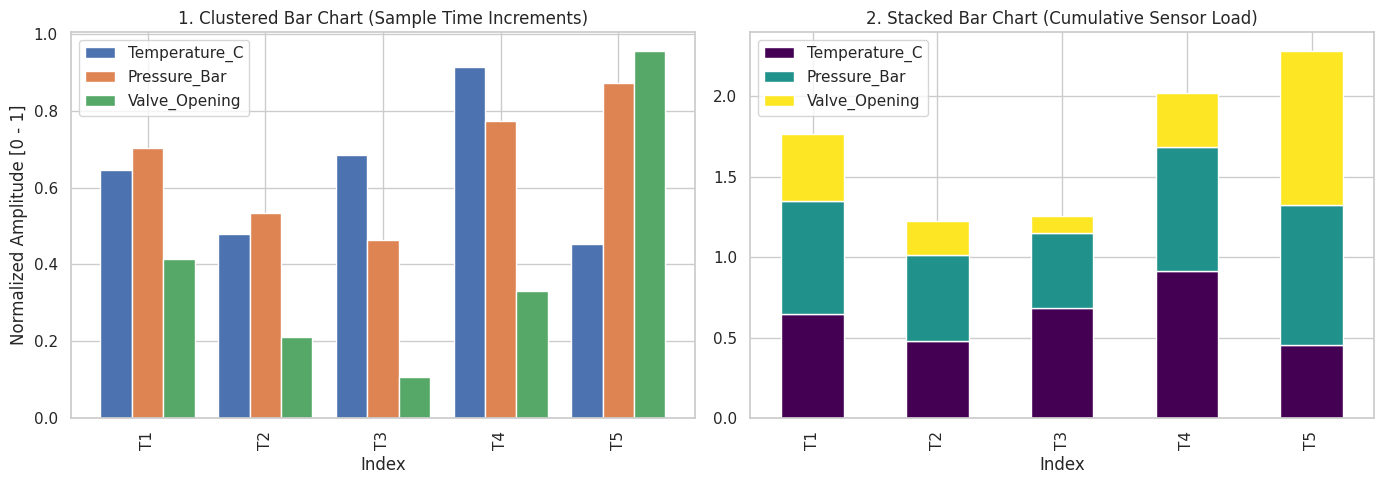

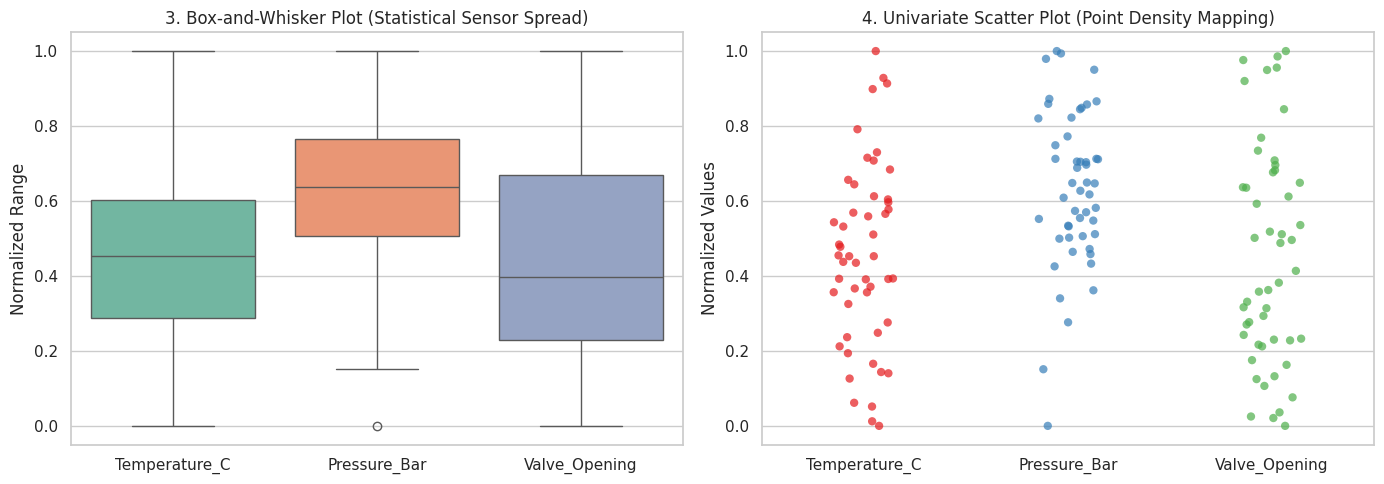

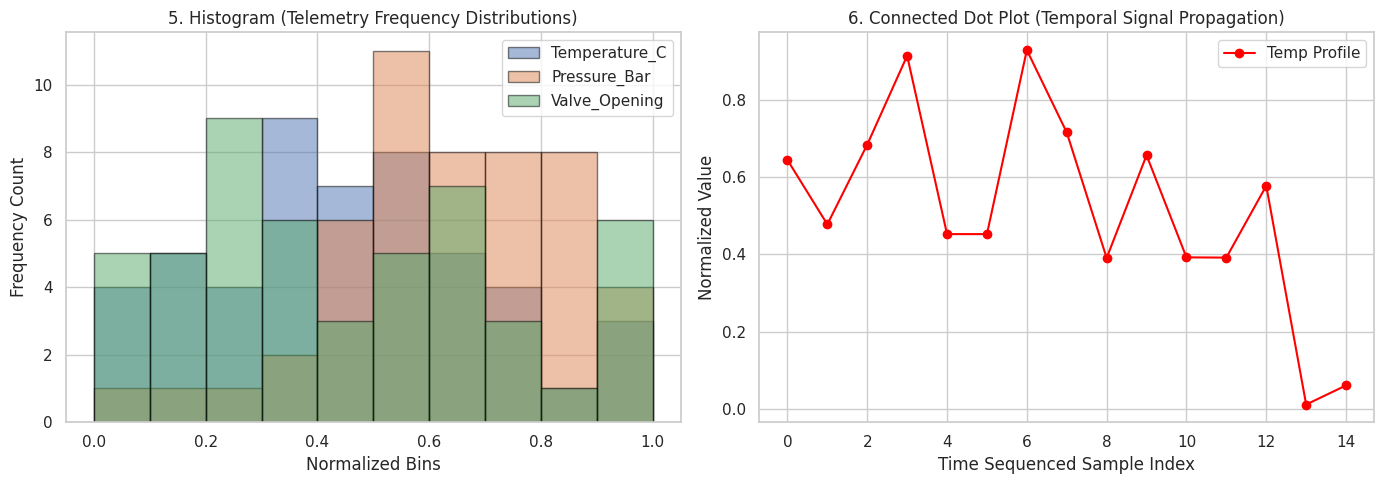

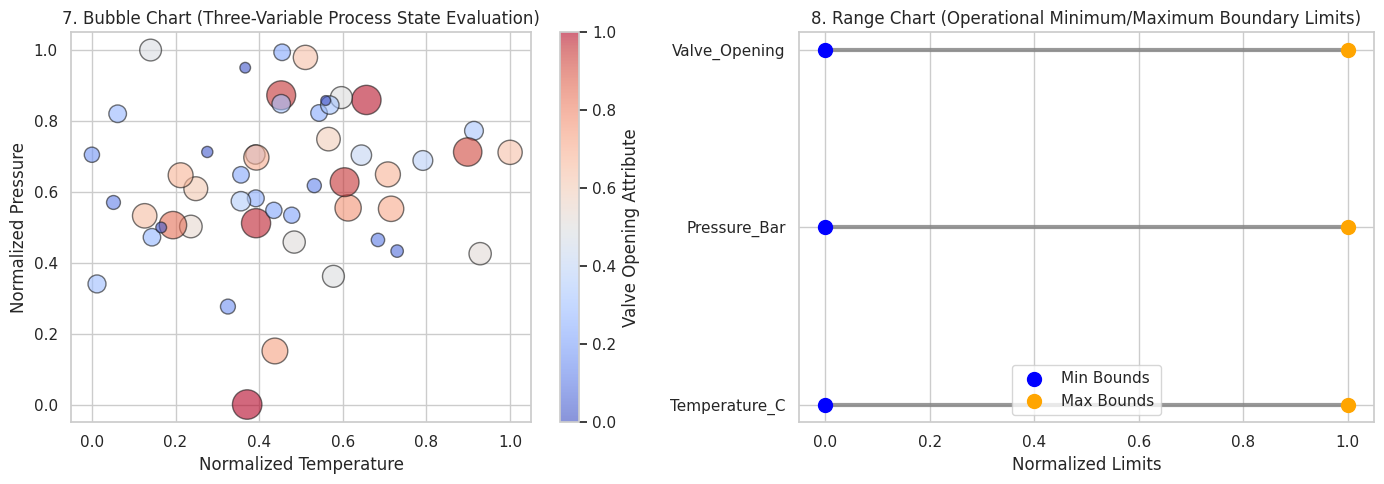

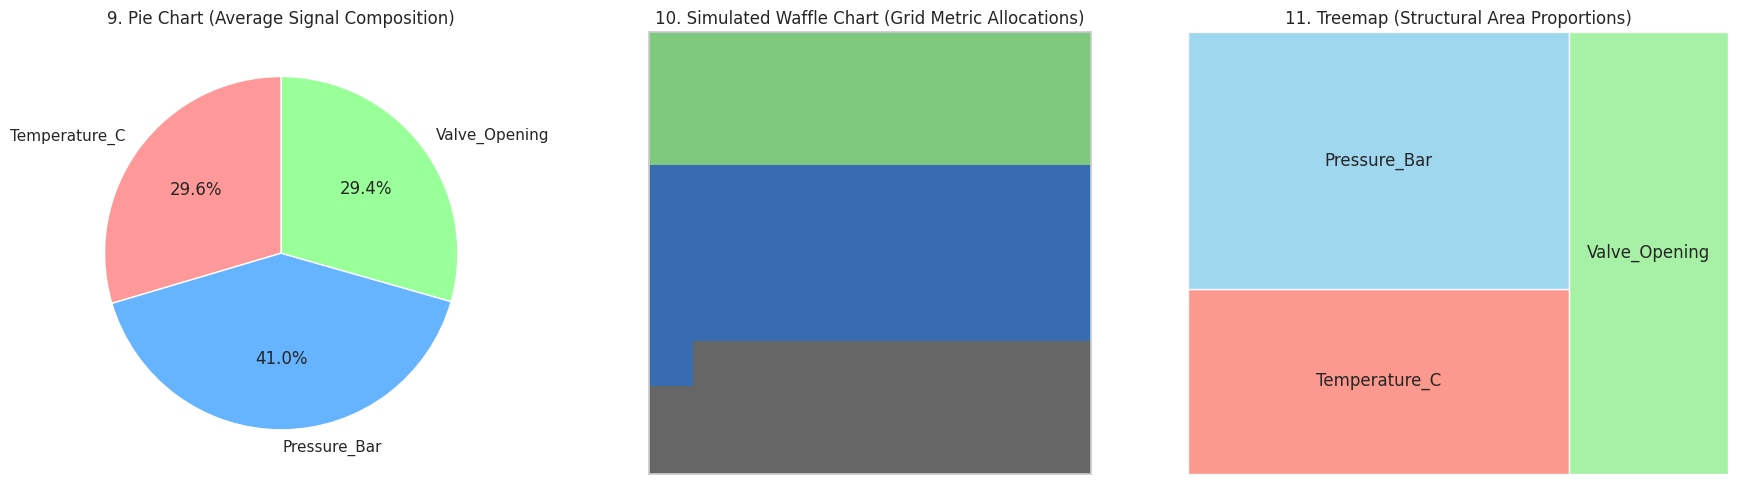

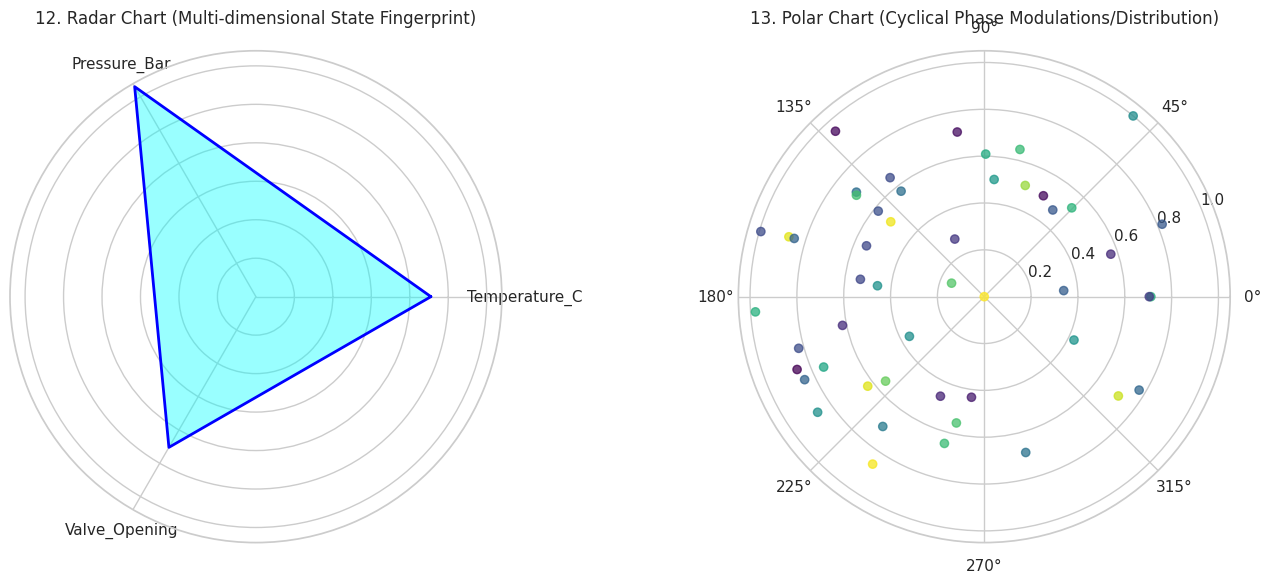

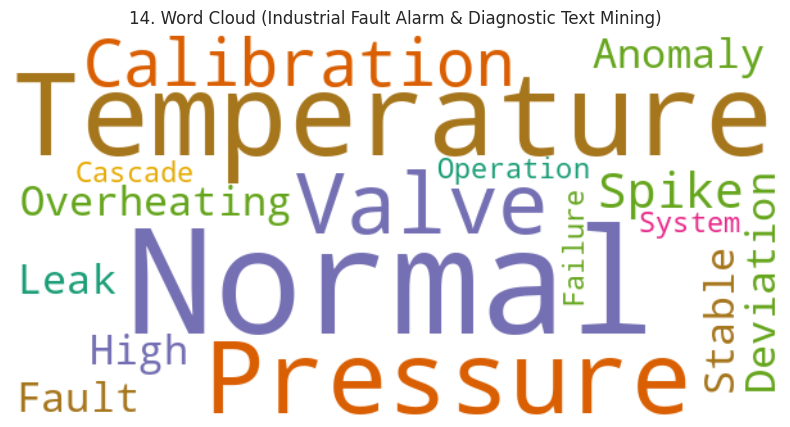


[NOTE ON PICTOGRAMS]: Traditional pictograms utilize custom icon graphics (e.g., repeating drawing files 
of a valve or thermometer) to display quantitative metrics. In core laboratory programming arrays, 
these are optimally served using grid arrays (like the developed Waffle Chart) or via standard 
web application dashboards utilizing specialized icon font rendering sets.


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from wordcloud import WordCloud
import squarify  # For Treemaps

# Set style for high-quality instrumentation reports
sns.set(style="whitegrid")
np.random.seed(42)

# =====================================================================
# STEP 1: GENERATE EIE CASE STUDY DATASET & PERFORM NORMALIZATION
# =====================================================================
# Simulating continuous industrial sensor telemetry over 50 time increments
data_length = 50
timestamps = pd.date_range(start="2026-10-22 08:00", periods=data_length, freq="min")

raw_data = {
    'Timestamp': timestamps,
    'Temperature_C': np.random.normal(210, 15, data_length), # 180 to 240 Range
    'Pressure_Bar': np.random.normal(4.5, 0.8, data_length),  # 2.5 to 6.5 Range
    'Valve_Opening': np.random.uniform(20, 90, data_length)   # 20% to 90% Scale
}

df_raw = pd.DataFrame(raw_data)
features = ['Temperature_C', 'Pressure_Bar', 'Valve_Opening']

# Execute Min-Max Data Normalization (Rescaling features strictly between 0 and 1)
scaler = MinMaxScaler()
df_normalized = df_raw.copy()
df_normalized[features] = scaler.fit_transform(df_raw[features])

# Print head check for data validation
print("--- Normalized EIE Telemetry Sample Data ---")
print(df_normalized.head().round(3))

# Calculate summary means for categorical chart representations
mean_metrics = df_normalized[features].mean()

# =====================================================================
# STEP 2: GENERATING THE 2-D LAB CHART SUITE
# =====================================================================

# --- 1. Clustered Bar Chart & Stacked Bar Chart ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sample_df = df_normalized.head(5).copy() # Use subset for scannable bar visual
sample_df['Index'] = [f"T{i}" for i in range(1, 6)]

# Clustered Bar Chart
sample_df.plot(x='Index', y=features, kind='bar', ax=axes[0], width=0.8)
axes[0].set_title("1. Clustered Bar Chart (Sample Time Increments)")
axes[0].set_ylabel("Normalized Amplitude [0 - 1]")

# Stacked Bar Chart
sample_df.plot(x='Index', y=features, kind='bar', stacked=True, ax=axes[1], colormap='viridis')
axes[1].set_title("2. Stacked Bar Chart (Cumulative Sensor Load)")
plt.tight_layout()
plt.show()


# --- 2. Box-and-Whisker Plot & Univariate Scatter Plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box-and-Whisker Plot
sns.boxplot(data=df_normalized[features], ax=axes[0], palette="Set2")
axes[0].set_title("3. Box-and-Whisker Plot (Statistical Sensor Spread)")
axes[0].set_ylabel("Normalized Range")

# Univariate Scatter Plot (Strip Plot representation)
sns.stripplot(data=df_normalized[features], ax=axes[1], jitter=0.15, size=6, palette="Set1", alpha=0.7)
axes[1].set_title("4. Univariate Scatter Plot (Point Density Mapping)")
axes[1].set_ylabel("Normalized Values")
plt.tight_layout()
plt.show()


# --- 3. Histogram & Connected Dot Plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (Distribution Overlap)
for col in features:
    axes[0].hist(df_normalized[col], bins=10, alpha=0.5, label=col, edgecolor='black')
axes[0].set_title("5. Histogram (Telemetry Frequency Distributions)")
axes[0].set_xlabel("Normalized Bins")
axes[0].set_ylabel("Frequency Count")
axes[0].legend()

# Connected Dot Plot (Time Series Telemetry Profile)
dot_sample = df_normalized.head(15) # First 15 points for visual clarity
axes[1].plot(dot_sample.index, dot_sample['Temperature_C'], marker='o', linestyle='-', color='red', label='Temp Profile')
axes[1].set_title("6. Connected Dot Plot (Temporal Signal Propagation)")
axes[1].set_xlabel("Time Sequenced Sample Index")
axes[1].set_ylabel("Normalized Value")
axes[1].legend()
plt.tight_layout()
plt.show()


# --- 4. Bubble Chart & Range Chart ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bubble Chart (X: Temp, Y: Pressure, Size: Valve Opening)
bubble_size = df_normalized['Valve_Opening'] * 400 + 50 # Amplify size variant
scatter = axes[0].scatter(df_normalized['Temperature_C'], df_normalized['Pressure_Bar'],
                         s=bubble_size, c=df_normalized['Valve_Opening'], cmap='coolwarm', alpha=0.6, edgecolors='k')
axes[0].set_title("7. Bubble Chart (Three-Variable Process State Evaluation)")
axes[0].set_xlabel("Normalized Temperature")
axes[0].set_ylabel("Normalized Pressure")
fig.colorbar(scatter, ax=axes[0], label='Valve Opening Attribute')

# Range Chart (Min to Max spread display)
ranges = df_normalized[features].agg(['min', 'max']).T
axes[1].hlines(y=ranges.index, xmin=ranges['min'], xmax=ranges['max'], color='grey', alpha=0.8, linewidth=3)
axes[1].scatter(ranges['min'], ranges.index, color='blue', s=100, label='Min Bounds', zorder=3)
axes[1].scatter(ranges['max'], ranges.index, color='orange', s=100, label='Max Bounds', zorder=3)
axes[1].set_title("8. Range Chart (Operational Minimum/Maximum Boundary Limits)")
axes[1].set_xlabel("Normalized Limits")
axes[1].legend()
plt.tight_layout()
plt.show()


# --- 5. Pie Chart, Waffle Chart, and Treemap ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Pie Chart (Mean Sensor Representation)
axes[0].pie(mean_metrics, labels=features, autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99'], startangle=90)
axes[0].set_title("9. Pie Chart (Average Signal Composition)")

# Waffle Chart (Manual Matrix block layout simulation)
# Simulating a 10x10 grid based on mean metrics percentages
total_tiles = 100
proportions = (mean_metrics / mean_metrics.sum() * total_tiles).round().astype(int)
waffle_grid = np.zeros((10, 10))
current_idx = 0
for cat_idx, count in enumerate(proportions):
    waffle_grid.flat[current_idx:current_idx+count] = cat_idx + 1
    current_idx += count
axes[1].imshow(waffle_grid, cmap='Accent', aspect='equal')
axes[1].set_title("10. Simulated Waffle Chart (Grid Metric Allocations)")
axes[1].grid(False)
axes[1].set_xticks([]); axes[1].set_yticks([])

# Treemap
squarify.plot(sizes=mean_metrics.values, label=features, color=["salmon", "skyblue", "lightgreen"], alpha=0.8, ax=axes[2])
axes[2].set_title("11. Treemap (Structural Area Proportions)")
axes[2].axis('off')
plt.tight_layout()
plt.show()


# --- 6. Radar Chart & Polar Chart ---
# Prepping variables for circular geometric charts
labels = np.array(features)
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
# Complete the structural loop for the circular radar path
angles += angles[:1]
radar_values = mean_metrics.values.tolist()
radar_values += radar_values[:1]

fig = plt.figure(figsize=(14, 6))

# Radar Chart
ax_radar = fig.add_subplot(121, polar=True)
ax_radar.fill(angles, radar_values, color='cyan', alpha=0.4)
ax_radar.plot(angles, radar_values, color='blue', linewidth=2)
ax_radar.set_yticklabels([])
ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(labels)
ax_radar.set_title("12. Radar Chart (Multi-dimensional State Fingerprint)", pad=20)

# Polar Chart (Scatter mapping in circular coordinates)
ax_polar = fig.add_subplot(122, polar=True)
polar_angles = df_normalized['Temperature_C'] * 2 * np.pi # Treat normalized data as angles
ax_polar.scatter(polar_angles, df_normalized['Pressure_Bar'], c=df_normalized['Valve_Opening'], cmap='viridis', alpha=0.75)
ax_polar.set_title("13. Polar Chart (Cyclical Phase Modulations/Distribution)", pad=20)
plt.tight_layout()
plt.show()


# --- 7. Word Cloud & Pictogram Reference Description ---
# Generate a text corpus based on physical operational events for EIE text mining
fault_text = " ".join([
    "Normal Normal Temperature Normal Pressure Spike Valve Overheating Normal Anomaly",
    "Pressure Deviation Normal Calibration Calibration Fault Temperature Temperature High",
    "Normal Valve Leak Temperature Normal Pressure Stable Operation Cascade System Failure"
])
wordcloud = WordCloud(width=600, height=300, background_color='white', colormap='Dark2').generate(fault_text)

plt.figure(figsize=(12, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("14. Word Cloud (Industrial Fault Alarm & Diagnostic Text Mining)")
plt.show()

# --- 15. Note on Pictograms ---
print("\n[NOTE ON PICTOGRAMS]: Traditional pictograms utilize custom icon graphics (e.g., repeating drawing files ")
print("of a valve or thermometer) to display quantitative metrics. In core laboratory programming arrays, ")
print("these are optimally served using grid arrays (like the developed Waffle Chart) or via standard ")
print("web application dashboards utilizing specialized icon font rendering sets.")


** Experiment 6: Multi-dimensional data visualization**

**Case Study Context: Industrial Distillation Column Process Monitoring**

In modern industrial automation, an instrumentation engineer rarely looks at a single sensor parameter in isolation. In a distillation column or chemical reactor, multiple physical properties interact simultaneously. For this case study, we simulate a multi-sensor array tracking a process run over time:
* Temperature (°C): Thermal state of the process chamber.
* Pressure (Bar): Force exerted within the containment vessel.
* Flow Rate (LPM): Feed velocity moving through the process loop.
* Control Valve Position (% Open): The physical mechanical correction applied by the controller.
* Process Efficiency Status (Target Variable): Categorical health indicator (Optimal, Warning, or Critical Fault).

This experiment implements four major engineering visualization techniques to view 4-Dimensional and 5-Dimensional states on a standard 2-D canvas:
1. 3D Scatter Plot with Color Mapping (4-D Visual): Maps Temp, Pressure, and Flow Rate on physical 3D space, using color as the 4th dimension.
2. Pair Plot Matrix with Class Hue (Multi-D Correlation): Builds a grid comparing every sensor against every other sensor simultaneously.
3. Parallel Coordinates Plot (High-Dimensional Profile): Renders a line signature for each telemetry frame across all sensor terminals to isolate fault tracking.
4. Radar / Spider Chart Profile (Dimensional Attribute Footprint): Projects a closed geometric polygon mapping average device constraints.



* Aim: To configure advanced multi-dimensional data visualization architectures using Python to monitor complex process parameters and isolate system failures.
* Discussion & Engineering Insights:
	1. 3D Color Mapping (4-D/5-D Workspace): Standard scatter charts limit engineers to 2 dimensions. By utilizing an X, Y, Z Cartesian framework alongside color spectrum tracking (c=Valve_Opening_Pct), a total of 4 continuous physical domains are evaluated on a flat canvas. Adding marker shapes creates a 5th dimension (System_Status), showing exactly where extreme values collide to cause operational faults.
	2. Pair Plot Grid: The scatter grid reveals sensor cross-correlations. For example, as the green data clumps group cleanly, a clear linear coupling is visible between high temperatures and structural valve corrections.
	3. Parallel Coordinates: This graph displays entire process signatures as lines rather than points. It clearly highlights operational profiles: normal operations trace a low-lying green band, whereas faults show a distinct signature—climbing sharply in temperature and pressure while plunging in flow rate.


--- 1. Multi-Sensor Process Telemetry Matrix Loaded ---
                Temperature_C  Pressure_Bar  Flow_Rate_LPM  Valve_Opening_Pct
System_Status                                                                
Critical Fault         240.56          5.76           7.97              90.76
Optimal                178.80          3.16          12.60              45.40
Warning                206.43          4.59          13.82              63.70




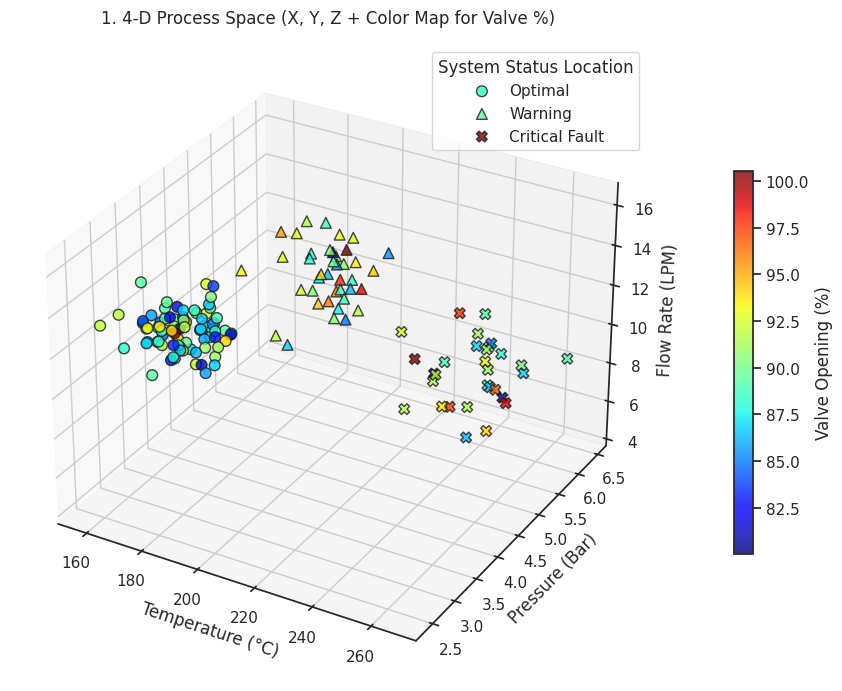

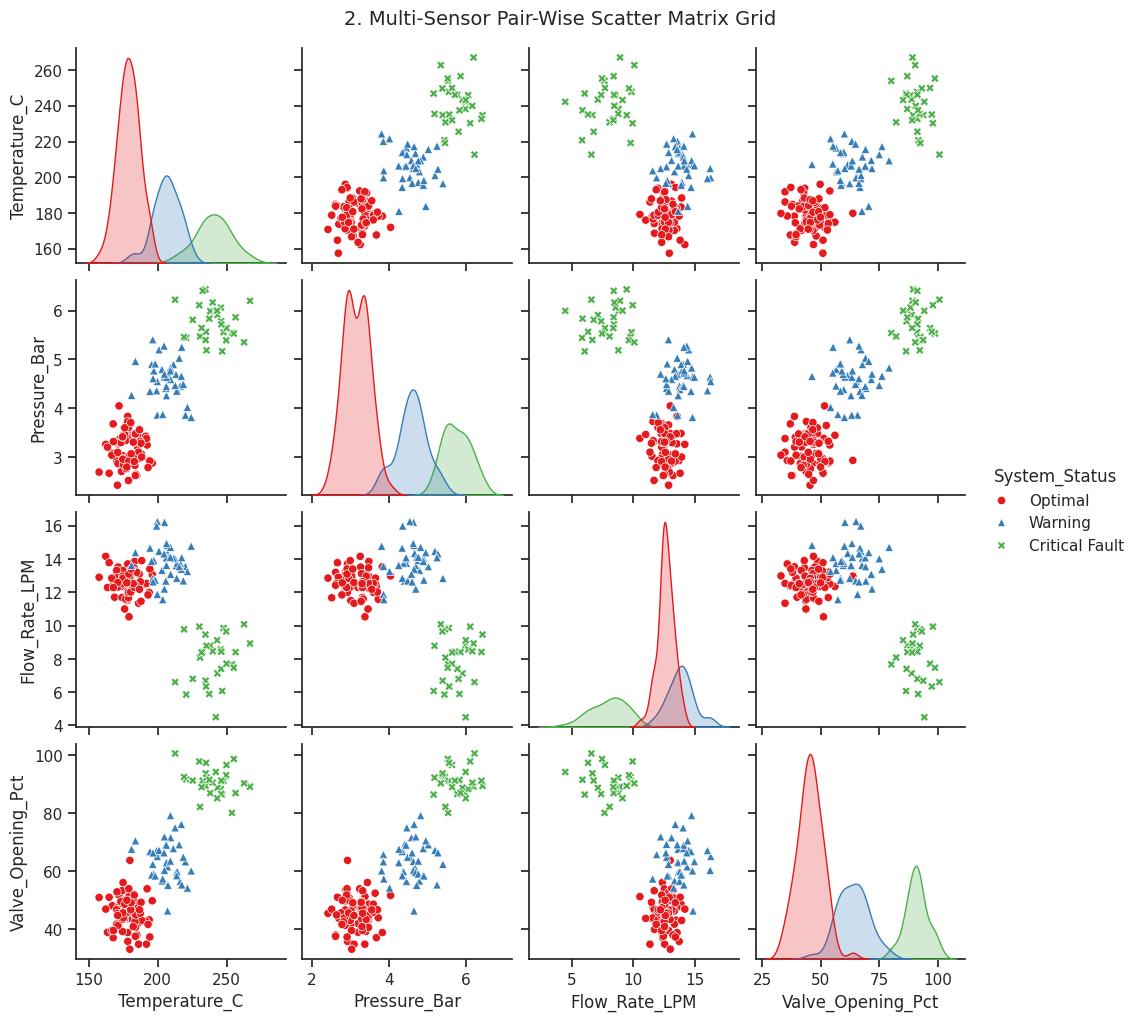

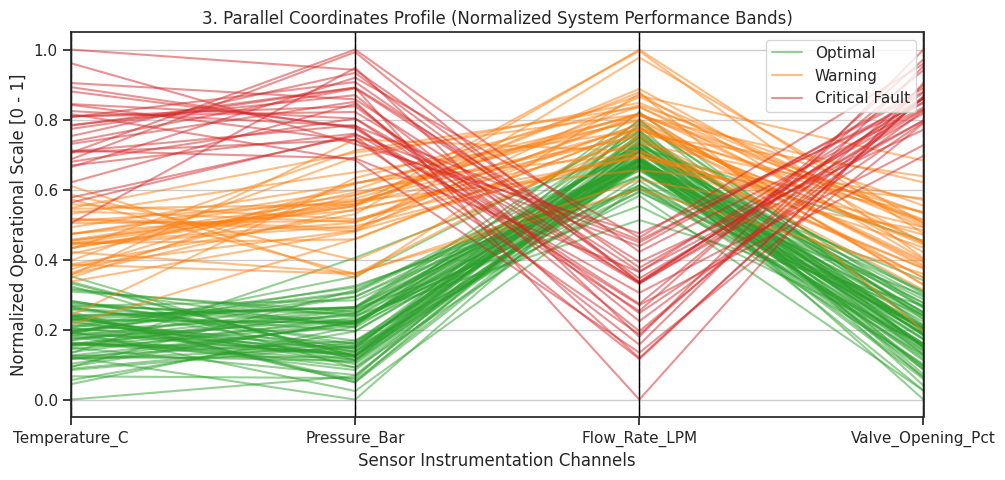

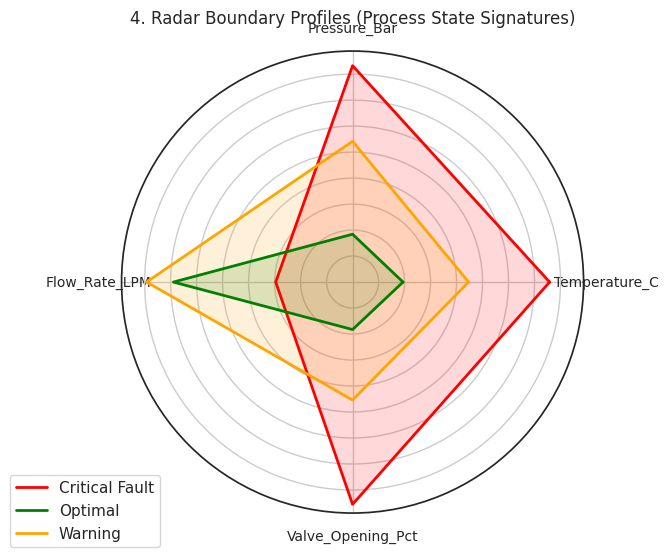

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import parallel_coordinates
from sklearn.preprocessing import MinMaxScaler

# Apply clear, professional publication theme for laboratory records
sns.set_theme(style="ticks")
np.random.seed(33)

# =====================================================================
# STEP 1: GENERATE MULTI-DIMENSIONAL EIE TELEMETRY DATASET
# =====================================================================
num_samples = 150

# 1. Simulate physical metrics for normal optimal operation
normal_temp = np.random.normal(loc=180, scale=8, size=80)
normal_press = np.random.normal(loc=3.2, scale=0.3, size=80)
normal_flow = np.random.normal(loc=12.5, scale=0.8, size=80)
normal_valve = np.random.normal(loc=45, scale=5, size=80)
normal_status = ['Optimal'] * 80

# 2. Simulate metrics for process pressure build-up warning states
warning_temp = np.random.normal(loc=205, scale=10, size=40)
warning_press = np.random.normal(loc=4.5, scale=0.4, size=40)
warning_flow = np.random.normal(loc=14.0, scale=1.1, size=40)
warning_valve = np.random.normal(loc=65, scale=8, size=40)
warning_status = ['Warning'] * 40

# 3. Simulate sensor failure / system thermal runaway anomalies
fault_temp = np.random.normal(loc=245, scale=12, size=30)
fault_press = np.random.normal(loc=5.8, scale=0.5, size=30)
fault_flow = np.random.normal(loc=8.0, scale=1.5, size=30)  # Flow drops due to restriction
fault_valve = np.random.normal(loc=90, scale=4, size=30)   # Valve forced wide open
fault_status = ['Critical Fault'] * 30

# Assemble into combined structural dataframe
df = pd.DataFrame({
    'Temperature_C': np.concatenate([normal_temp, warning_temp, fault_temp]),
    'Pressure_Bar': np.concatenate([normal_press, warning_press, fault_press]),
    'Flow_Rate_LPM': np.concatenate([normal_flow, warning_flow, fault_flow]),
    'Valve_Opening_Pct': np.concatenate([normal_valve, warning_valve, fault_valve]),
    'System_Status': np.concatenate([normal_status, warning_status, fault_status])
})

print("--- 1. Multi-Sensor Process Telemetry Matrix Loaded ---")
print(df.groupby('System_Status').mean().round(2))
print("\n" + "="*80 + "\n")


# =====================================================================
# VISUALIZATION 1: 3D SCATTER PLOT WITH COLOR MAPPING (4-DIMENSIONAL DATA)
# =====================================================================
# Dim 1: Temp (X), Dim 2: Pressure (Y), Dim 3: Flow (Z), Dim 4: Valve Position (Color)
fig = plt.figure(figsize=(9, 7))
ax3d = fig.add_subplot(111, projection='3d')

# Map status to marker shapes for an extra 5th dimension (Shape)
status_markers = {'Optimal': 'o', 'Warning': '^', 'Critical Fault': 'X'}

for status, marker in status_markers.items():
    sub_df = df[df['System_Status'] == status]
    scatter = ax3d.scatter(
        sub_df['Temperature_C'],
        sub_df['Pressure_Bar'],
        sub_df['Flow_Rate_LPM'],
        c=sub_df['Valve_Opening_Pct'],
        cmap='jet',
        marker=marker,
        s=60,
        edgecolors='k',
        alpha=0.8,
        label=status
    )

ax3d.set_title("1. 4-D Process Space (X, Y, Z + Color Map for Valve %)", fontsize=12, pad=15)
ax3d.set_xlabel("Temperature (°C)")
ax3d.set_ylabel("Pressure (Bar)")
ax3d.set_zlabel("Flow Rate (LPM)")
fig.colorbar(scatter, ax=ax3d, shrink=0.6, pad=0.1, label='Valve Opening (%)')
ax3d.legend(title="System Status Location")
plt.tight_layout()
plt.show()


# =====================================================================
# VISUALIZATION 2: PAIR PLOT CORRELATION GRID MATRIX (MULTI-D RELATIONSHIPS)
# =====================================================================
# Plots every numerical vector combination to expose linear and non-linear multi-sensor cross-talk.
pair_grid = sns.pairplot(df, hue='System_Status', palette='Set1', diag_kind='kde', markers=['o', '^', 'X'])
pair_grid.fig.suptitle("2. Multi-Sensor Pair-Wise Scatter Matrix Grid", y=1.02, fontsize=14)
plt.show()


# =====================================================================
# VISUALIZATION 3: PARALLEL COORDINATES PLOT (HIGH-DIMENSIONAL ALIGNMENT)
# =====================================================================
# Scales attributes to view line patterns across distinct sensor nodes.
plt.figure(figsize=(11, 5))
# Normalize numerical columns to a unified 0-1 range to align axes cleanly
features = ['Temperature_C', 'Pressure_Bar', 'Flow_Rate_LPM', 'Valve_Opening_Pct']
df_norm = df.copy()
df_norm[features] = MinMaxScaler().fit_transform(df[features])

parallel_coordinates(df_norm, 'System_Status', color=('#2ca02c', '#ff7f0e', '#d62728'), alpha=0.5, linewidth=1.5)
plt.title("3. Parallel Coordinates Profile (Normalized System Performance Bands)", fontsize=12)
plt.ylabel("Normalized Operational Scale [0 - 1]")
plt.xlabel("Sensor Instrumentation Channels")
plt.grid(True, axis='x', linestyle='--', color='gray', alpha=0.7)
plt.show()


# =====================================================================
# VISUALIZATION 4: MULTI-VARIABLE RADAR / SPIDER CHART COMPARISON
# =====================================================================
# Compares the centroid footprint signatures of each target system state.
mean_profiles = df_norm.groupby('System_Status').mean()

labels = list(mean_profiles.columns)
num_vars = len(labels)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1] # Close the polar geometric path loop

fig = plt.figure(figsize=(7, 6))
ax_radar = fig.add_subplot(111, polar=True)

colors_map = {'Optimal': 'green', 'Warning': 'orange', 'Critical Fault': 'red'}

for status in mean_profiles.index:
    values = mean_profiles.loc[status].values.tolist()
    values += values[:1] # Complete visual circle loop closure

    ax_radar.plot(angles, values, linewidth=2, label=status, color=colors_map[status])
    ax_radar.fill(angles, values, alpha=0.15, color=colors_map[status])

ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(labels, fontsize=10)
ax_radar.set_yticklabels([]) # Hide absolute grids for spatial parity
plt.title("4. Radar Boundary Profiles (Process State Signatures)", pad=20, fontsize=12)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.show()



**Experiment 7: Graph data visualization**

network graph visualization is used to model industrial Fieldbus topologies (like Modbus, Profibus, or HART grids), SCADA communication routing, and distributed sensor networks. It enables instrumentation engineers to visualize complex physical interconnections, audit hardware routing, and isolate single points of failure (e.g., a critical master gateway node dropping out).
This case study maps a distributed industrial factory SCADA framework containing Master Gateways, PLCs, Sub-controllers, and local Transducers.



* Aim: To design and implement a network graph visualization paradigm using Python to map, evaluate, and audit the communication routing topography of a distributed industrial SCADA framework.
* Engineering Context:
	1. Structural Taxonomy: Industrial topologies are inherently relational. Representing this via a DiGraph (Directed Graph) allows instrumentation engineers to verify telemetry pathways from localized field transducers all the way up to processing host engines.
	2. Centrality Matrix Analysis: In network graph logic, Degree Centrality quantifies structural dependencies. Isolating high-centrality intersections programmatically helps identify high-risk bottlenecks where system line degradation would cause complete channel failure.
	3. Edge Weights Representation: By assigning transmission line loop metrics (e.g., cable length in meters) directly to edge weights, this platform aids physical signal integrity calculations, predicting voltage attenuation over serial RS-485 loop interfaces.


In [9]:
pip install networkx

Note: you may need to restart the kernel to use updated packages.


--- EIE SCADA Topology Network Graph Performance Metrics ---
Total Configured Instrumentation Hardware Units (Nodes): 11
Total Active Physical Telemetry Data Links (Edges): 10
Critical Communication Hub Detected: Gateway_Alpha (Centrality: 0.30)




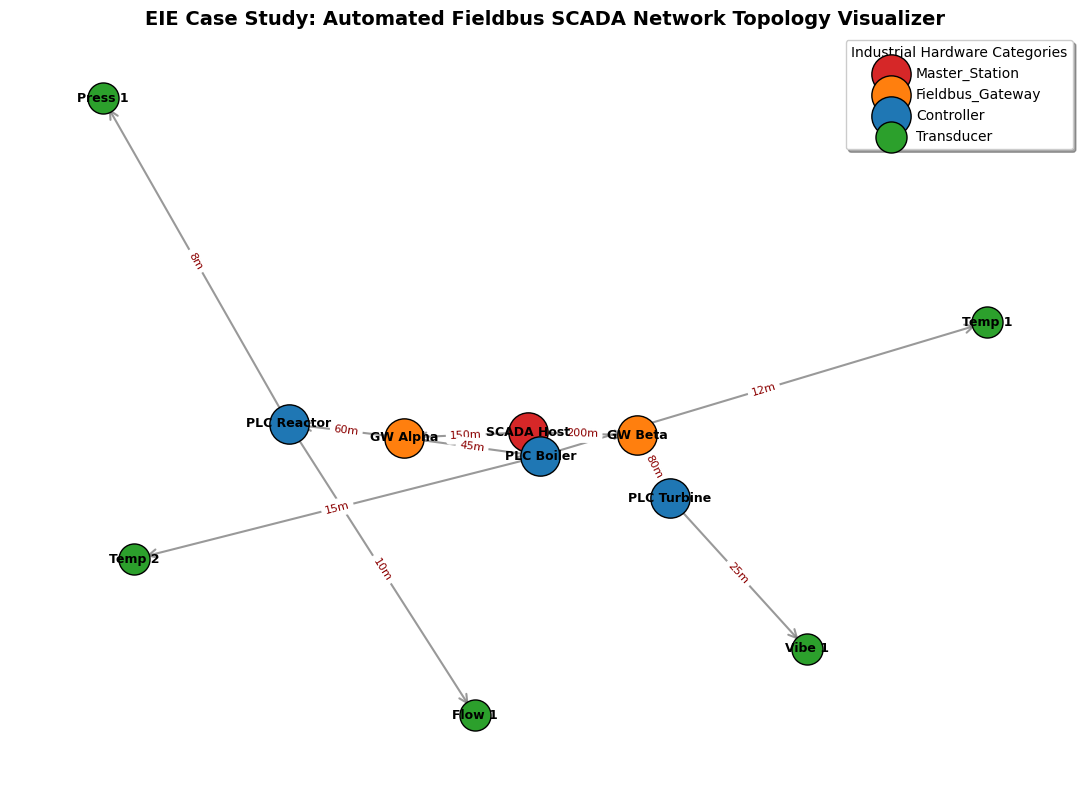

In [10]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# Set up a clean, professional visualization design for laboratory records
plt.style.use('default')

# =====================================================================
# STEP 1: DEFINE EIE CASE STUDY DATA (SCADA Telemetry Network Elements)
# =====================================================================
# Defining physical instrumentation hardware nodes and their structural categories
hardware_nodes = {
    'Central_SCADA': {'type': 'Master_Station', 'label': 'SCADA Host'},
    'Gateway_Alpha': {'type': 'Fieldbus_Gateway', 'label': 'GW Alpha'},
    'Gateway_Beta':  {'type': 'Fieldbus_Gateway', 'label': 'GW Beta'},
    'PLC_Boiler':    {'type': 'Controller', 'label': 'PLC Boiler'},
    'PLC_Reactor':   {'type': 'Controller', 'label': 'PLC Reactor'},
    'PLC_Turbine':   {'type': 'Controller', 'label': 'PLC Turbine'},
    'Temp_Sensor_1': {'type': 'Transducer', 'label': 'Temp 1'},
    'Temp_Sensor_2': {'type': 'Transducer', 'label': 'Temp 2'},
    'Press_Sensor':  {'type': 'Transducer', 'label': 'Press 1'},
    'Flow_Sensor':   {'type': 'Transducer', 'label': 'Flow 1'},
    'Vibe_Sensor':   {'type': 'Transducer', 'label': 'Vibe 1'}
}

# Defining the directional physical connections (Ethernet / Modbus RS-485 Serial Links)
# The weights represent transmission line distances (meters)
communication_links = [
    ('Central_SCADA', 'Gateway_Alpha', 150),
    ('Central_SCADA', 'Gateway_Beta', 200),
    ('Gateway_Alpha', 'PLC_Boiler', 45),
    ('Gateway_Alpha', 'PLC_Reactor', 60),
    ('Gateway_Beta', 'PLC_Turbine', 80),
    ('PLC_Boiler', 'Temp_Sensor_1', 12),
    ('PLC_Boiler', 'Temp_Sensor_2', 15),
    ('PLC_Reactor', 'Press_Sensor', 8),
    ('PLC_Reactor', 'Flow_Sensor', 10),
    ('PLC_Turbine', 'Vibe_Sensor', 25)
]

# =====================================================================
# STEP 2: BUILD INTER-DEVICE GRAPH ARCHITECTURE
# =====================================================================
# Initialize NetworkX Directed Graph (DiGraph matches true industrial signal flow direction)
G = nx.DiGraph()

# Inject nodes along with attributes
for node, attrs in hardware_nodes.items():
    G.add_node(node, **attrs)

# Inject edges along with communications weight constraints
for source, target, distance in communication_links:
    G.add_edge(source, target, weight=distance)

# =====================================================================
# STEP 3: PERFORM TOPOLOGY ROUTING AUDITS (LAB METRICS)
# =====================================================================
print("--- EIE SCADA Topology Network Graph Performance Metrics ---")
print(f"Total Configured Instrumentation Hardware Units (Nodes): {G.number_of_nodes()}")
print(f"Total Active Physical Telemetry Data Links (Edges): {G.number_of_edges()}")

# Calculate degree centrality (identifies the most critical routing junction point)
centrality = nx.degree_centrality(G)
most_critical_node = max(centrality, key=centrality.get)
print(f"Critical Communication Hub Detected: {most_critical_node} (Centrality: {centrality[most_critical_node]:.2f})")
print("\n" + "="*75 + "\n")

# =====================================================================
# STEP 4: GRAPH PLOTTING & VISUAL COLOR-MAPPING
# =====================================================================
plt.figure(figsize=(11, 8))

# Select a specialized structural force-directed layout to avoid node overlap
pos = nx.spring_layout(G, seed=42, k=0.8)

# Grouping and coloring nodes dynamically based on industrial hardware type
type_colors = {
    'Master_Station': '#d62728',     # Red for main SCADA system
    'Fieldbus_Gateway': '#ff7f0e',   # Orange for field gateways
    'Controller': '#1f77b4',         # Blue for PLCs
    'Transducer': '#2ca02c'          # Green for field sensors
}

# Render nodes grouped by structural category
for hardware_type, color in type_colors.items():
    node_list = [n for n, attr in G.nodes(data=True) if attr['type'] == hardware_type]
    nx.draw_networkx_nodes(G, pos, nodelist=node_list, node_color=color,
                           node_size=800 if hardware_type != 'Transducer' else 500,
                           edgecolors='black', label=hardware_type)

# Render directional signal communication lines (arrows indicate flow of telemetry)
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=15, edge_color='gray', width=1.5, alpha=0.8)

# Inject node text tags
node_labels = nx.get_node_attributes(G, 'label')
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=9, font_weight='bold', font_color='black')

# Overlay length/weight attributes onto the communication routing channels
edge_labels = nx.get_edge_attributes(G, 'weight')
formatted_edge_labels = {k: f"{v}m" for k, v in edge_labels.items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=formatted_edge_labels, font_size=8, font_color='darkred')

# Finalize Lab Chart presentation attributes
plt.title("EIE Case Study: Automated Fieldbus SCADA Network Topology Visualizer", fontsize=14, fontweight='bold')
plt.legend(title="Industrial Hardware Categories", loc="upper right", frameon=True, shadow=True)
plt.axis('off')  # Hide spatial bounding box grids
plt.tight_layout()
plt.show()
